In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Models
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# Evaluation
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import joblib

In [2]:
df = pd.read_csv("../data/processed_data.csv")

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,...,Units,Gross Profit,Cost,Year,Month,Month Name,Day,Day of Week,Profit Margin (%),Selling Price per Unit
0,1,US-2021-103800-CHO-MIL-31000,2024-01-03,30-06-2026,Standard Class,103800,United States,Houston,Texas,77095,...,2,4.22,2.28,2024,1,January,3,Wednesday,64.923077,3.25
1,2,US-2021-112326-CHO-TRI-54000,2024-01-04,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,...,2,4.90,2.60,2024,1,January,4,Thursday,65.333333,3.75
2,3,US-2021-112326-CHO-NUT-13000,2024-01-04,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,...,3,7.47,3.00,2024,1,January,4,Thursday,71.346705,3.49
3,4,US-2021-112326-CHO-SCR-58000,2024-01-04,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,...,3,7.50,3.30,2024,1,January,4,Thursday,69.444444,3.60
4,5,US-2021-141817-CHO-TRI-54000,2024-01-05,05-07-2026,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,...,3,7.35,3.90,2024,1,January,5,Friday,65.333333,3.75


In [3]:
df["Order Date"] = pd.to_datetime(df["Order Date"])

In [4]:
ml_df = df[[
    "Division",
    "Region",
    "Units",
    "Month",
    "Day",
    "Sales"
]].copy()

ml_df.head()

,Division,Region,Units,Month,Day,Sales
0,Chocolate,Interior,2,1,3,6.50
1,Chocolate,Interior,2,1,4,7.50
2,Chocolate,Interior,3,1,4,10.47
3,Chocolate,Interior,3,1,4,10.80
4,Chocolate,Atlantic,3,1,5,11.25


In [5]:
division_encoder = LabelEncoder()
region_encoder = LabelEncoder()

ml_df["Division"] = division_encoder.fit_transform(ml_df["Division"])
ml_df["Region"] = region_encoder.fit_transform(ml_df["Region"])

ml_df.head()

,Division,Region,Units,Month,Day,Sales
0,0,2,2,1,3,6.50
1,0,2,2,1,4,7.50
2,0,2,3,1,4,10.47
3,0,2,3,1,4,10.80
4,0,0,3,1,5,11.25


In [6]:
X = ml_df.drop("Sales", axis=1)
y = ml_df["Sales"]

print(X.shape)
print(y.shape)

(10194, 5)
(10194,)


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print(X_train.shape)
print(X_test.shape)

(8155, 5)
(2039, 5)


In [8]:
lr = LinearRegression()
lr.fit(X_train, y_train)

lr_pred = lr.predict(X_test)

In [9]:
dt = DecisionTreeRegressor(random_state=42)

dt.fit(X_train, y_train)

dt_pred = dt.predict(X_test)

In [10]:
rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

In [11]:
def evaluate_model(name, y_true, y_pred):
    print("=" * 40)
    print(name)

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    print("MAE :", round(mae, 4))
    print("RMSE:", round(rmse, 4))
    print("R²  :", round(r2, 4))

In [12]:
evaluate_model("Linear Regression", y_test, lr_pred)

evaluate_model("Decision Tree", y_test, dt_pred)

evaluate_model("Random Forest", y_test, rf_pred)

Linear Regression
MAE : 1.4235
RMSE: 6.0688
R²  : 0.6482
Decision Tree
MAE : 1.5286
RMSE: 8.9291
R²  : 0.2385
Random Forest
MAE : 1.4032
RMSE: 6.8336
R²  : 0.554


In [13]:
import joblib

joblib.dump(lr, "../models/sales_prediction_model.pkl")

print("Linear Regression model saved successfully!")

Linear Regression model saved successfully!


In [14]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": lr.coef_
})

feature_importance = feature_importance.sort_values(
    by="Coefficient",
    key=abs,
    ascending=False
)

feature_importance

,Feature,Coefficient
0,Division,11.623645
2,Units,3.739535
1,Region,0.116011
3,Month,0.025607
4,Day,-0.020837


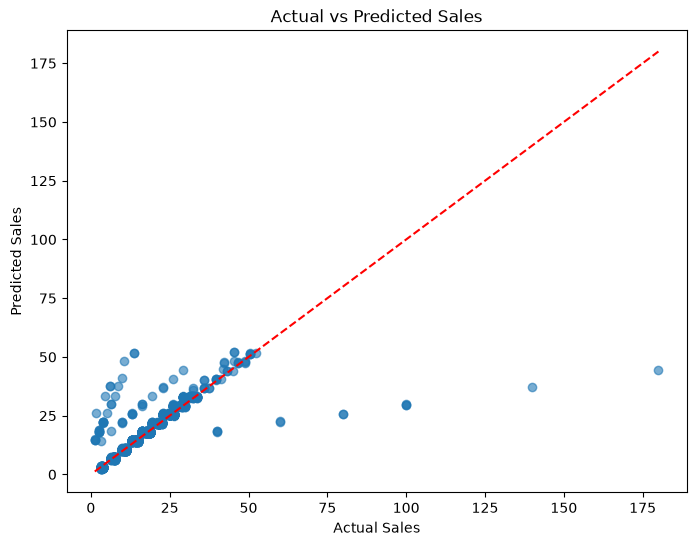

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
plt.scatter(y_test, lr_pred, alpha=0.6)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales")

plt.show()

In [16]:
import joblib

model = joblib.load("models/random_forest_profit.pkl")

print(model.feature_names_in_)

FileNotFoundError: [Errno 2] No such file or directory: 'models/random_forest_profit.pkl'

In [17]:
import os
print(os.getcwd())

d:\Projects\Factory Optimisation System\notebooks


In [18]:
import joblib

model = joblib.load(r"D:\Projects\Factory Optimisation System\models\random_forest_profit.pkl")
print(model.feature_names_in_)

['Division' 'Region' 'Units' 'Sales' 'Cost']


In [19]:
print(model.feature_names_in_)

['Division' 'Region' 'Units' 'Sales' 'Cost']


In [20]:
sales = st.number_input(
    "Sales ($)",
    min_value=0.0,
    value=10.0,
    step=0.1
)

cost = st.number_input(
    "Cost ($)",
    min_value=0.0,
    value=5.0,
    step=0.1
)

NameError: name 'st' is not defined